# Lab 8 — Experiment notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab08.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click -> Save image as..., or `plt.savefig('fig1.png', dpi=150)`).
Report figures 1-3 are required by the report template.


In [1]:
import sys
sys.path.insert(0, '../src')
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import lab08

X, y, groups = lab08.load_data('../data/delivery_late.csv')
data = (X, y, groups)

table = lab08.run_ablation(lab08.BASE_CONFIG, lab08.FACTORS, lab08.SEEDS, data=data)
ablation = table.groupby('variant', sort=False)['f1'].agg(['mean', 'std']).round(4)

y_val, y_pred, groups_val = lab08.base_predictions(lab08.SEED)
errors = lab08.error_analysis(y_val, y_pred, groups_val)

records = [lab08.run_config(cfg, seed, data=data)
           for cfg in (lab08.BASE_CONFIG, lab08.CHALLENGER_CONFIG)
           for seed in lab08.SEEDS]
ranking = lab08.summarize(records)
ablation


,mean,std
variant,,
base,0.6439,0.0230
features=with_region,0.7355,0.0270
features=core,0.4741,0.0302
model=tree,0.5292,0.0431
class_weight=balanced,0.6787,0.0180
scale=False,0.6358,0.0210


## Plot 1 — Overall accuracy against per-slice accuracy

The point of the figure is the distance between the overall line and the worst bar, and the
sample count printed on each bar. A slice with fewer than 30 samples is not evidence.


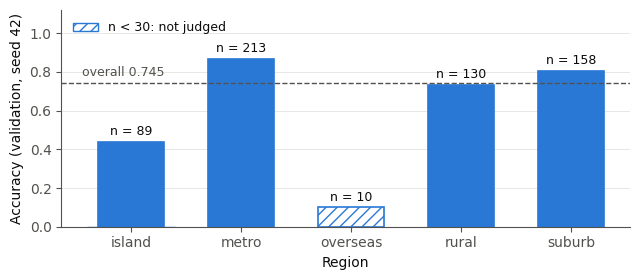

In [2]:
# ============ Plot 1 ============
from pathlib import Path
FIG = Path('../figures'); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, INK, MUTED, BAND = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'text.color': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 10})

names = list(errors['slices'])
acc = [errors['slices'][k]['accuracy'] for k in names]
ns = [errors['slices'][k]['n'] for k in names]
overall = errors['overall']['accuracy']

fig, ax = plt.subplots(figsize=(6.5, 2.9))
bars = ax.bar(names, acc, width=0.6, color=BLUE, edgecolor=BLUE, linewidth=1.2)
for bar, n in zip(bars, ns):
    if n < 30:                                   # too small to judge: hollow + hatched
        bar.set_facecolor('white'); bar.set_hatch('///')
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02, f'n = {n}',
            ha='center', va='bottom', fontsize=9, color=INK)
ax.axhline(overall, ls='--', lw=1, color=MUTED)
ax.text(-0.45, overall + 0.02, f'overall {overall:.3f}', ha='left', va='bottom',
        fontsize=9, color=MUTED)
ax.bar([0], [0], color='white', edgecolor=BLUE, hatch='///', label='n < 30: not judged')
ax.legend(loc='upper left', frameon=False, fontsize=9)
ax.set_ylim(0, 1.12); ax.set_ylabel('Accuracy (validation, seed 42)')
ax.set_xlabel('Region'); ax.grid(axis='y', color=BAND, lw=0.6); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(FIG / 'fig1.png', dpi=200); plt.show()


## Plot 2 — Ablation: which factors clear the seed noise

Each variant differs from the base in exactly one factor. The error bar is one sample standard
deviation over `lab08.SEEDS`. A bar whose error bar reaches the base band has not been shown to
do anything.


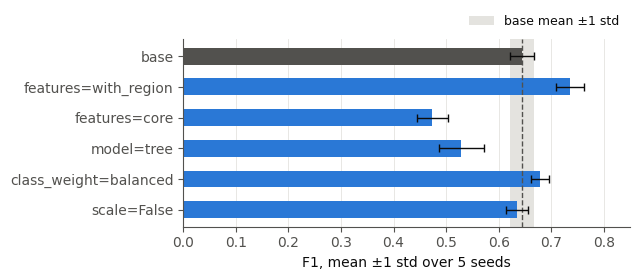

In [3]:
# ============ Plot 2 ============
order = list(ablation.index)                     # run order: base first
ypos = np.arange(len(order))[::-1]
b_mean, b_std = ablation.loc['base', 'mean'], ablation.loc['base', 'std']

fig, ax = plt.subplots(figsize=(6.5, 2.9))
ax.axvspan(b_mean - b_std, b_mean + b_std, color=BAND, lw=0, label='base mean ±1 std')
ax.axvline(b_mean, ls='--', lw=1, color=MUTED)
ax.barh(ypos, ablation['mean'], xerr=ablation['std'], height=0.55,
        color=[MUTED if v == 'base' else BLUE for v in order],
        error_kw=dict(ecolor=INK, capsize=3, lw=1))
ax.set_yticks(ypos, order)
ax.set_xlim(0, 0.85); ax.set_xlabel(f'F1, mean ±1 std over {len(lab08.SEEDS)} seeds')
ax.legend(loc='lower right', bbox_to_anchor=(1, 1.0), frameon=False, fontsize=9)
ax.grid(axis='x', color=BAND, lw=0.6); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(FIG / 'fig2.png', dpi=200); plt.show()


## Plot 3 — Seed spread of two configurations

Same data as `ranking`, but one point per seed instead of one number per configuration. If the
two clouds interleave, the ranking between them is not a result yet.


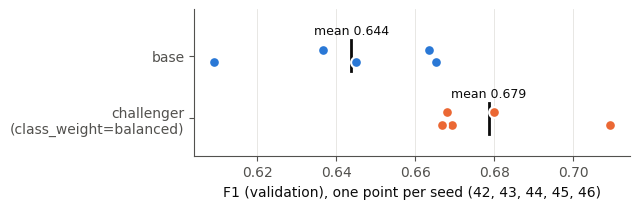

,config_id,n_seeds,mean,std,min,max,rank,overlaps_best
0,class_weight=balanced|features=numeric|model=l...,5,0.6787,0.018,0.6667,0.7094,1,True
1,class_weight=None|features=numeric|model=logre...,5,0.6439,0.023,0.6091,0.6652,2,True


In [4]:
# ============ Plot 3 ============
base_id = lab08.config_id(lab08.BASE_CONFIG)
groups3 = [('base', BLUE, [r for r in records if r['config_id'] == base_id]),
           ('challenger\n(class_weight=balanced)', ORANGE,
            [r for r in records if r['config_id'] != base_id])]

fig, ax = plt.subplots(figsize=(6.5, 2.2))
for y, (label, color, recs) in zip([1, 0], groups3):
    vals = np.array([r['metrics']['f1'] for r in recs])
    jitter = np.where(np.argsort(np.argsort(vals)) % 2, 0.1, -0.1)  # neighbours alternate up/down
    ax.scatter(vals, y + jitter, s=60, color=color, edgecolor='white',
               linewidth=1.5, zorder=3)
    ax.plot([vals.mean()] * 2, [y - 0.25, y + 0.25], color=INK, lw=2, zorder=2)
    ax.text(vals.mean(), y + 0.3, f'mean {vals.mean():.3f}', ha='center', va='bottom',
            fontsize=9, color=INK)
ax.set_yticks([1, 0], [g[0] for g in groups3]); ax.set_ylim(-0.6, 1.75)
ax.set_xlabel(f'F1 (validation), one point per seed {lab08.SEEDS}')
ax.grid(axis='x', color=BAND, lw=0.6); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(FIG / 'fig3.png', dpi=200); plt.show()
ranking
